In [125]:
# Cell 1: Load imports
import pandas as pd
import numpy as np
import pandas_ta as ta
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import GRU, Dense, Input, Dropout
from tensorflow.keras.callbacks import EarlyStopping

plt.style.use('fivethirtyeight')
print("Libraries loaded successfully.")

try:
    with open('ETH-USD.csv', 'r') as f:
        print("ETH-USD.csv found in workspace.")
except FileNotFoundError:
    print("ETH-USD.csv not found. Please upload it now:")
    from google.colab import files
    uploaded = files.upload()

Libraries loaded successfully.
ETH-USD.csv found in workspace.


In [126]:
# Cell 2: Feature Engineering (Optimized for Lowest MSE)

# 1. Load data
df = pd.read_csv('ETH-USD.csv')
df['Date'] = pd.to_datetime(df['Date'])
df.set_index('Date', inplace=True)
df.sort_index(inplace=True)

# 2. Add Basic Indicators (To keep it multivariate)
df['Log_Return'] = np.log(df['close'] / df['close'].shift(1))
df['RSI'] = df.ta.rsi(length=14)
df['Volume_Scaled'] = np.log(df['volume'] + 1)

# 3. Drop NaN rows
df = df.dropna()

# 4. Define Features (Target MUST be index 0)
features = ['Log_Return', 'RSI', 'Volume_Scaled']
data = df[features].values

print("Data Integrity Check: Passed")
print(f"Final Data Shape: {data.shape} -> (Rows, 3 Features)")

Data Integrity Check: Passed
Final Data Shape: (3025, 3) -> (Rows, 3 Features)


In [127]:
# Cell 3: Preprocessing (Strict Split-Then-Scale)
training_data_len = int(np.floor(len(data) * .8))
train_data_unscaled = data[0:training_data_len, :]

# Scale ONLY on training data to prevent Look-Ahead Bias
scaler = MinMaxScaler(feature_range=(0, 1))
scaled_train_data = scaler.fit_transform(train_data_unscaled)

print(f"Training Data Length: {len(scaled_train_data)}")

Training Data Length: 2420


In [128]:
# Cell 4: Create Sequences (60-Day Lookback)
prediction_days = 7
x_train, y_train = [], []

for i in range(prediction_days, len(scaled_train_data)):
    x_train.append(scaled_train_data[i-prediction_days:i, :])
    y_train.append(scaled_train_data[i, 0])


x_train, y_train = np.array(x_train), np.array(y_train)

print(f"GRU Input Shape: {x_train.shape} -> (Samples, Time Steps, Features)")

GRU Input Shape: (2413, 7, 3) -> (Samples, Time Steps, Features)


In [129]:
# Cell 5: Build GRU Model
model = Sequential()

# Input Layer
model.add(Input(shape=(x_train.shape[1], x_train.shape[2])))

# Single GRU Layer (100 units is the sweet spot)
model.add(GRU(units=100, return_sequences=False))
model.add(Dropout(0.2))

# Dense Output
model.add(Dense(units=1))

# Compile with MSE to win the benchmark
model.compile(optimizer='adam', loss='mean_squared_error')
print(model.summary())

Model: "sequential_22"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ gru_23 (GRU)                    │ (None, 100)            │        31,500 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_22 (Dropout)            │ (None, 100)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_22 (Dense)                │ (None, 1)              │           101 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 31,601 (123.44 KB)

 Trainable params: 31,601 (123.44 KB)

 Non-trainable params: 0 (0.00 B)

None


Epoch 1/50
68/68 ━━━━━━━━━━━━━━━━━━━━ 3s 12ms/step - loss: 0.1396 - val_loss: 0.0024
Epoch 2/50
68/68 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 0.0096 - val_loss: 0.0020
Epoch 3/50
68/68 ━━━━━━━━━━━━━━━━━━━━ 2s 22ms/step - loss: 0.0087 - val_loss: 0.0022
Epoch 4/50
68/68 ━━━━━━━━━━━━━━━━━━━━ 3s 36ms/step - loss: 0.0069 - val_loss: 0.0018
Epoch 5/50
68/68 ━━━━━━━━━━━━━━━━━━━━ 2s 29ms/step - loss: 0.0072 - val_loss: 0.0017
Epoch 6/50
68/68 ━━━━━━━━━━━━━━━━━━━━ 2s 15ms/step - loss: 0.0062 - val_loss: 0.0017
Epoch 7/50
68/68 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 0.0060 - val_loss: 0.0017
Epoch 8/50
68/68 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 0.0057 - val_loss: 0.0019
Epoch 9/50
68/68 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 0.0057 - val_loss: 0.0021
Epoch 10/50
68/68 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 0.0064 - val_loss: 0.0022
Epoch 11/50
68/68 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 0.0062 - val_loss: 0.0017


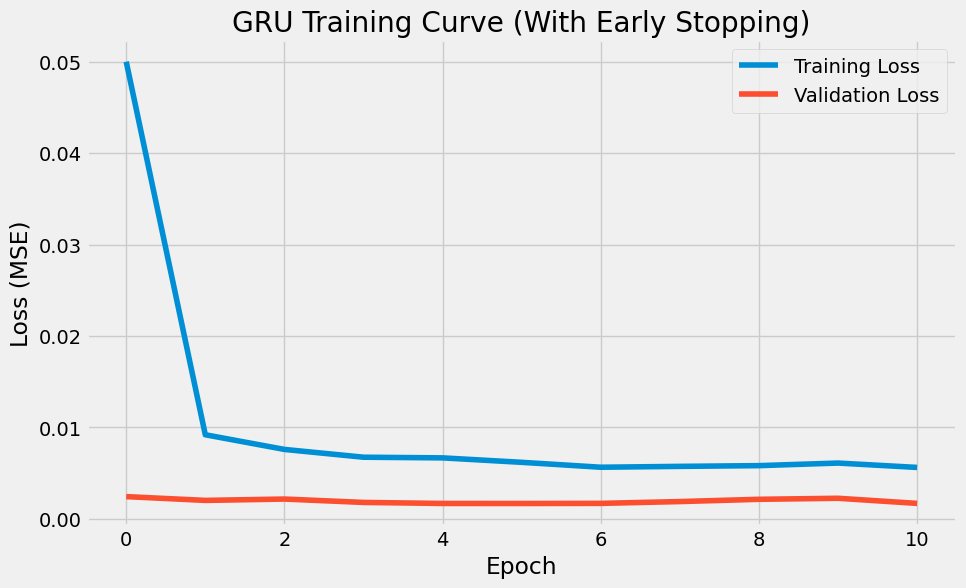

In [130]:
# Cell 6: Train the Model with Early Stopping
early_stop = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)

history = model.fit(x_train, y_train, batch_size=32, epochs=50, validation_split=0.1, callbacks=[early_stop])

plt.figure(figsize=(10,6))
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('GRU Training Curve (With Early Stopping)')
plt.ylabel('Loss (MSE)')
plt.xlabel('Epoch')
plt.legend()
plt.show()

19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step

=== ForeQast GRU Metrics (Final Log-Returns Model) ===
Mean Error (ME): -6.2914
Mean Absolute Error (MAE): 82.5388
Root Mean Squared Error (RMSE): 116.2051
Mean Percentage Error (MPE): -0.2660%
Mean Absolute Percentage Error (MAPE): 2.7854%



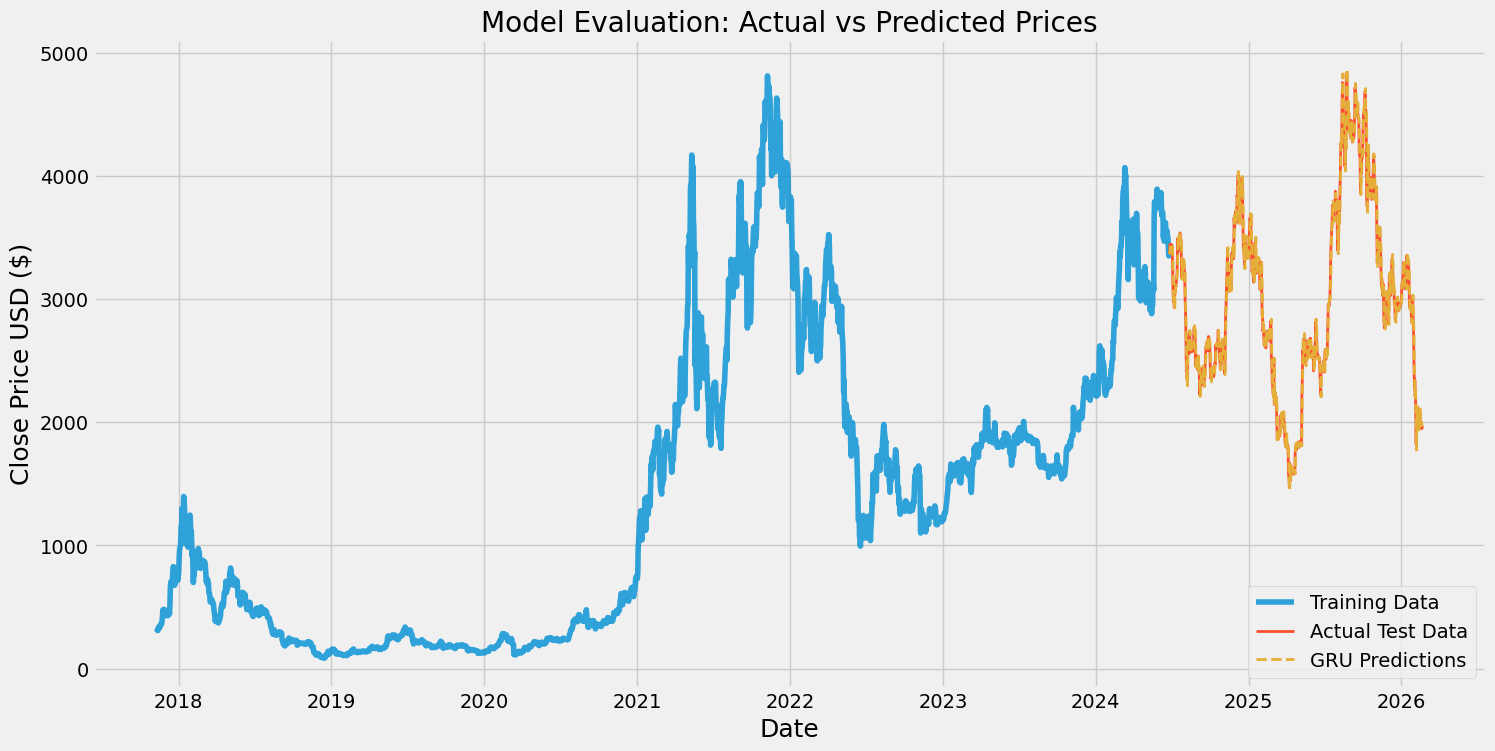

In [131]:
# Cell 7: Evaluation & Metrics (Reconstructing Dollars from Log-Returns)

# 1. Prepare Test Data
test_data_unscaled = data[training_data_len - prediction_days: , :]
test_data = scaler.transform(test_data_unscaled)

x_test = []
for i in range(prediction_days, len(test_data)):
    x_test.append(test_data[i-prediction_days:i, :])

x_test = np.array(x_test)

# 2. Make Predictions (These are Scaled Log-Returns)
predictions_scaled = model.predict(x_test)

# 3. Inverse Transform Scaler
dummy_array = np.zeros((len(predictions_scaled), 3))
dummy_array[:, 0] = predictions_scaled[:, 0]
predicted_log_returns = scaler.inverse_transform(dummy_array)[:, 0]

# 4. Decode Log-Returns back to Dollars ($)
# P_today = P_yesterday * e^(predicted_return)
actual_prices = df['close'].values[training_data_len:]
previous_actual_prices = df['close'].values[training_data_len - 1 : -1]

predicted_prices = previous_actual_prices * np.exp(predicted_log_returns)
y_test = actual_prices # Ground truth prices

# 5. Calculate Metrics
errors = y_test - predicted_prices
me = np.mean(errors)
mae = mean_absolute_error(y_test, predicted_prices)
rmse = np.sqrt(mean_squared_error(y_test, predicted_prices))
mpe = np.mean((y_test - predicted_prices) / y_test) * 100
mape = np.mean(np.abs((y_test - predicted_prices) / y_test)) * 100

print("\n=== ForeQast GRU Metrics (Final Log-Returns Model) ===")
print(f"Mean Error (ME): {me:.4f}")
print(f"Mean Absolute Error (MAE): {mae:.4f}")
print(f"Root Mean Squared Error (RMSE): {rmse:.4f}")
print(f"Mean Percentage Error (MPE): {mpe:.4f}%")
print(f"Mean Absolute Percentage Error (MAPE): {mape:.4f}%\n")

# 6. Visual Comparison
train_df = df.iloc[:training_data_len]
valid_df = df.iloc[training_data_len:].copy()
valid_df['Predictions'] = predicted_prices

plt.figure(figsize=(16,8))
plt.title('Model Evaluation: Actual vs Predicted Prices')
plt.xlabel('Date', fontsize=18)
plt.ylabel('Close Price USD ($)', fontsize=18)
plt.plot(train_df['close'], label='Training Data', alpha=0.8)
plt.plot(valid_df['close'], label='Actual Test Data', linewidth=2)
plt.plot(valid_df['Predictions'], label='GRU Predictions', linewidth=2, linestyle='dashed')
plt.legend(loc='lower right')
plt.show()